In [1]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Flatten
from keras.applications.vgg16 import VGG16

In [2]:
conv_base = VGG16(
    weights='imagenet',
    include_top = False,
    input_shape=(150,150,3)
)

In [3]:
model = Sequential()

model.add(conv_base)
model.add(Flatten())
model.add(Dense(256,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [4]:
conv_base.trainable = False

In [6]:
from tensorflow.keras.utils import (
    array_to_img,
    img_to_array,
    load_img
)

In [11]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_dir = "Datasets/Data/train"
test_dir = "Datasets/Data/test"

batch_size = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(150, 150),
    batch_size=batch_size,
    class_mode='binary'
)

validation_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(150, 150),
    batch_size=batch_size,
    class_mode='binary'
)

Found 17934 images belonging to 2 classes.
Found 5000 images belonging to 2 classes.


In [12]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [17]:
history = model.fit(
    train_generator,
    epochs=2,
    validation_data=validation_generator
)

Epoch 1/2
561/561 ━━━━━━━━━━━━━━━━━━━━ 382s 681ms/step - accuracy: 0.8951 - loss: 0.2416 - val_accuracy: 0.9112 - val_loss: 0.2070
Epoch 2/2
561/561 ━━━━━━━━━━━━━━━━━━━━ 370s 660ms/step - accuracy: 0.9047 - loss: 0.2213 - val_accuracy: 0.9128 - val_loss: 0.2045


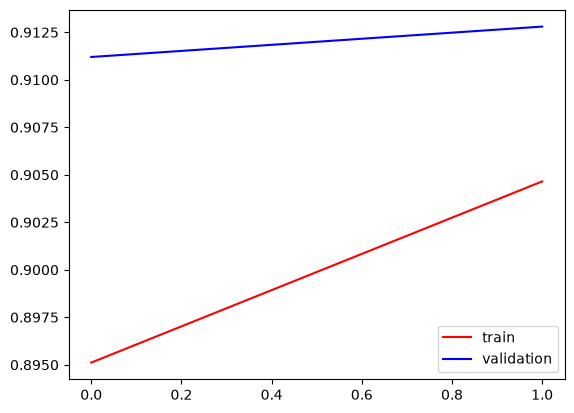

In [18]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

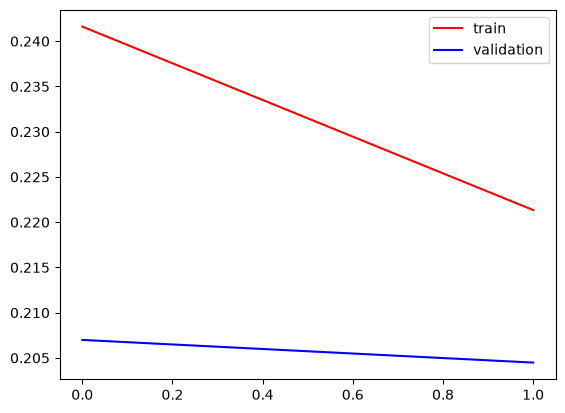

In [19]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()